<a href="https://colab.research.google.com/github/LennardBehmann/Intro-ML/blob/main/Homework_6/ML_HW6_P1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 6 Problem 1 - neuronal networks

**import libraries **

In [538]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import copy

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR

from sklearn.metrics import mean_squared_error, r2_score


**import dataset from github**

In [539]:
url = 'https://raw.githubusercontent.com/LennardBehmann/Intro-ML/refs/heads/main/Homework_6/Housing.csv'

df = pd.read_csv(url)

display(df.head())

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


**convert yes/no to binary values**

In [540]:
df_float = df.copy()
binary_columns = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'prefarea'
]
for column in binary_columns:
    df_float[column] = df_float[column].map({'yes': 1, 'no': 0})

df_float.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished


**furnishing status problem**

In [541]:

df_float['furnishingstatus'] = df_float['furnishingstatus'].map({'unfurnished':0, 'semi-furnished':1, 'furnished':2})
df_float.head()


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,2
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,2
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,2
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,2


**choose features**

In [542]:
features=['area','bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus' ]
X=df_float[features]
y=df['price']
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (545, 12)
y shape: (545,)


In [543]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("X samples:", len(X))
print("y samples:", len(y))

X shape: (545, 12)
y shape: (545,)
X samples: 545
y samples: 545


**Train and Test Split (80/20)**

In [544]:

# Split dataset into 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (436, 12)
X_test shape: (109, 12)
y_train shape: (436,)
y_test shape: (109,)


**Standardise**

In [545]:

# Standardize input features X
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)


# Standardize target values y
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))

y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1))


**conversion to tensors**

In [546]:

# Convert standardized data into PyTorch tensors

# Input features
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

# Target values
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32)

# Check tensor shapes
print("X_train_tensor shape:", X_train_tensor.shape)
print("y_train_tensor shape:", y_train_tensor.shape)
print("X_test_tensor shape:", X_test_tensor.shape)
print("y_test_tensor shape:", y_test_tensor.shape)


X_train_tensor shape: torch.Size([436, 12])
y_train_tensor shape: torch.Size([436, 1])
X_test_tensor shape: torch.Size([109, 12])
y_test_tensor shape: torch.Size([109, 1])


**Define models**

In [547]:
#model function
def create_model(input_number, output_number, hidden_layers):

    layers = []
    current_size = input_number

    # Create hidden layers
    for neurons in hidden_layers:
        layers.append(nn.Linear(current_size, neurons))
        layers.append(nn.ReLU())

        current_size = neurons

    # Create output layer
    layers.append(nn.Linear(current_size, output_number))

    # Build model
    model = nn.Sequential(*layers)

    return model



In [548]:

# Define model architectures
architectures = {
    "A": [5, 3, 2],
    "B": [3, 3, 3],
    "C": [2, 2, 2],
    "D": [4, 2]
}


In [549]:

# General loss function
loss_fn = nn.MSELoss()

# General optimizer function
def create_optimizer(model, learning_rate=0.005):
    return torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )



**train different models (A-D)**

In [550]:

def train_model(model, optimizer, loss_fn,
                X_train, y_train, X_eval, y_eval,
                n_epochs=10000, verbose=False):

    train_losses = []
    val_losses = []

    for epoch in range(n_epochs):

        # TRAINING
        model.train()

        predictions = model(X_train)
        train_loss = loss_fn(predictions, y_train)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        # EVALUATION
        model.eval()

        with torch.no_grad():

            # Calculate training and evaluation predictions
            train_predictions = model(X_train)
            eval_predictions = model(X_eval)

            # Calculate MSE losses
            train_loss_eval = loss_fn(
                train_predictions, y_train
            )

            eval_loss = loss_fn(
                eval_predictions, y_eval
            )

        # SAVE LOSSES
        train_losses.append(train_loss_eval.item())
        val_losses.append(eval_loss.item())

        # PRINT EVERY 500 EPOCHS
        if verbose and (epoch + 1) % 500 == 0:
            print(
                f"Epoch {epoch + 1}: "
                f"Train Loss = {train_loss_eval.item():.4f}, "
                f"Eval Loss = {eval_loss.item():.4f}"
            )

    return train_losses, val_losses


In [551]:

# Neural Network Training with 80/20 Split

# Define model configuration
best_name = "D"
best_lr = 0.01
final_seed = 42
final_epochs = 10000

# Set random seed
torch.manual_seed(final_seed)

# Create model
best_model = create_model(
    input_number=X_train_tensor.shape[1],
    output_number=1,
    hidden_layers=architectures[best_name]
)

# Create optimizer
optimizer = create_optimizer(
    best_model,
    learning_rate=best_lr
)

# Train model
train_losses, val_losses = train_model(
    best_model,
    optimizer,
    loss_fn,
    X_train_tensor,
    y_train_tensor,
    X_test_tensor,
    y_test_tensor,
    n_epochs=final_epochs,
    verbose=True
)

# Save training history
training_history = {
    "train_losses": train_losses,
    "val_losses": val_losses
}

# Display model configuration
print(f"\nModel: {best_name}")
print(f"Architecture: {architectures[best_name]}")
print(f"Learning Rate: {best_lr}")
print(f"Seed: {final_seed}")
print(f"Training Epochs: {final_epochs}")
print(f"Training Samples: {len(X_train)}")
print(f"Test Samples: {len(X_test)}")


Epoch 500: Train Loss = 0.3658, Eval Loss = 0.6809
Epoch 1000: Train Loss = 0.3298, Eval Loss = 0.6022
Epoch 1500: Train Loss = 0.3173, Eval Loss = 0.5834
Epoch 2000: Train Loss = 0.3049, Eval Loss = 0.5730
Epoch 2500: Train Loss = 0.2982, Eval Loss = 0.5725
Epoch 3000: Train Loss = 0.2921, Eval Loss = 0.5749
Epoch 3500: Train Loss = 0.2846, Eval Loss = 0.5747
Epoch 4000: Train Loss = 0.2757, Eval Loss = 0.5755
Epoch 4500: Train Loss = 0.2671, Eval Loss = 0.5730
Epoch 5000: Train Loss = 0.2603, Eval Loss = 0.5672
Epoch 5500: Train Loss = 0.2553, Eval Loss = 0.5636
Epoch 6000: Train Loss = 0.2520, Eval Loss = 0.5617
Epoch 6500: Train Loss = 0.2479, Eval Loss = 0.5595
Epoch 7000: Train Loss = 0.2458, Eval Loss = 0.5616
Epoch 7500: Train Loss = 0.2427, Eval Loss = 0.5650
Epoch 8000: Train Loss = 0.2412, Eval Loss = 0.5688
Epoch 8500: Train Loss = 0.2396, Eval Loss = 0.5735
Epoch 9000: Train Loss = 0.2381, Eval Loss = 0.5742
Epoch 9500: Train Loss = 0.2370, Eval Loss = 0.5738
Epoch 10000: 

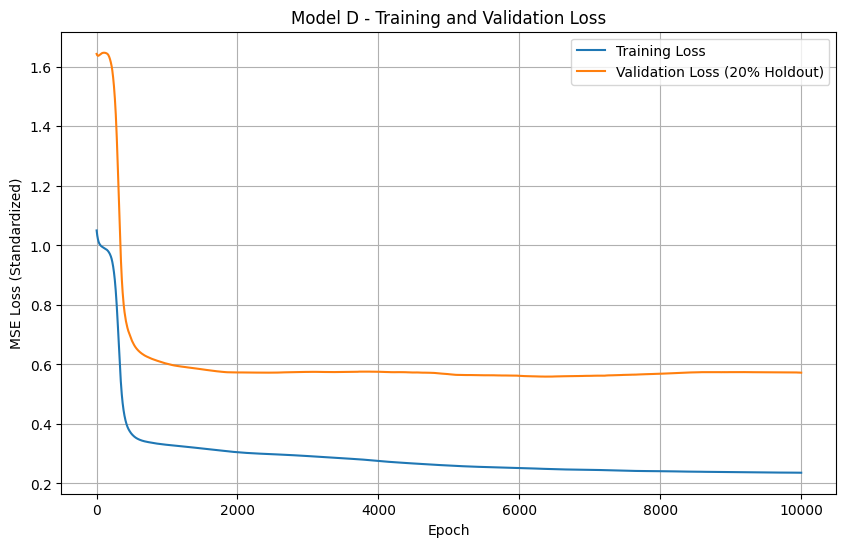

In [552]:

# Plot training and validation loss

epochs = range(
    1, len(training_history["train_losses"]) + 1
)

plt.figure(figsize=(10, 6))

# Training loss
plt.plot(
    epochs,
    training_history["train_losses"],
    label="Training Loss"
)

# Evaluation loss on the 20% holdout
plt.plot(
    epochs,
    training_history["val_losses"],
    label="Validation Loss (20% Holdout)"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss (Standardized)")
plt.title(
    f"Model {best_name} - Training and Validation Loss"
)

plt.legend()
plt.grid(True)
plt.show()


In [553]:

# Final Neural Network Test Evaluation

best_model.eval()

with torch.no_grad():
    test_predictions = best_model(X_test_tensor)

# Convert predictions back to original housing prices
y_pred = scaler_y.inverse_transform(
    test_predictions.cpu().numpy()
).ravel()

# True housing prices
y_true = y_test.to_numpy().ravel()

# Calculate regression metrics
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_true, y_pred)

# Display model configuration
print(f"Final Model: {best_name}")
print(f"Architecture: {architectures[best_name]}")
print(f"Learning Rate: {best_lr}")
print(f"Seed: {final_seed}")
print(f"Training Epochs: {final_epochs}")
print(f"Test Samples: {len(y_test)}\n")

# Display test metrics
print(f"Test MSE:  {mse:.2f}")
print(f"Test RMSE: {rmse:.2f}")
print(f"Test R²:   {r2:.4f}")


Final Model: D
Architecture: [4, 2]
Learning Rate: 0.01
Seed: 42
Training Epochs: 10000
Test Samples: 109

Test MSE:  1764691935232.00
Test RMSE: 1328417.08
Test R²:   0.6509


In [554]:

# Linear Regression with 80/20 Train-Test Split

# Create model
linear_model = LinearRegression()

# Train on 80% of the dataset
linear_model.fit(
    X_train_scaled,
    y_train_scaled.ravel()
)

# Display configuration
print("Linear Regression")
print(f"Training Samples: {len(X_train)}")
print(f"Test Samples: {len(X_test)}")
print(f"Input Features: {X_train_scaled.shape[1]}")


Linear Regression
Training Samples: 436
Test Samples: 109
Input Features: 12


In [555]:

# Support Vector Regression with 80/20 Train-Test Split

# Create SVR model
best_svr = SVR(
    kernel="rbf",
    C=1.0,
    epsilon=0.1,
    gamma="scale"
)

# Train on 80% of the dataset
best_svr.fit(
    X_train_scaled,
    y_train_scaled.ravel()
)

# Display configuration
print("Support Vector Regression")
print("Kernel: RBF")
print("Regularization C: 1.0")
print("Epsilon: 0.1")
print("Gamma: scale")
print(f"Training Samples: {len(X_train)}")
print(f"Test Samples: {len(X_test)}")


Support Vector Regression
Kernel: RBF
Regularization C: 1.0
Epsilon: 0.1
Gamma: scale
Training Samples: 436
Test Samples: 109


In [556]:

# FINAL MODEL COMPARISON

# True housing prices
y_true = y_test.to_numpy().ravel()

# Linear Regression predictions
linear_pred_scaled = linear_model.predict(X_test_scaled)

# SVR predictions
svr_pred_scaled = best_svr.predict(X_test_scaled)

# Neural Network predictions
best_model.eval()

with torch.no_grad():
    nn_pred_scaled = best_model(
        X_test_tensor
    ).cpu().numpy().ravel()


# Convert predictions back to original housing prices
linear_pred = scaler_y.inverse_transform(
    linear_pred_scaled.reshape(-1, 1)
).ravel()

svr_pred = scaler_y.inverse_transform(
    svr_pred_scaled.reshape(-1, 1)
).ravel()

nn_pred = scaler_y.inverse_transform(
    nn_pred_scaled.reshape(-1, 1)
).ravel()


# Function to calculate regression metrics
def evaluate_model(name, predictions):

    mse = mean_squared_error(y_true, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, predictions)

    return {
        "Model": name,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }


# Compare all three models
comparison_results = [
    evaluate_model("Neural Network", nn_pred),
    evaluate_model("Linear Regression", linear_pred),
    evaluate_model("SVR", svr_pred)
]

comparison_df = pd.DataFrame(comparison_results)

# Sort by lowest MSE
comparison_df = comparison_df.sort_values(
    "MSE",
    ascending=True
).reset_index(drop=True)

display(comparison_df)

print("Lowest Test MSE:", comparison_df.iloc[0]["Model"])
print(f"Test Samples: {len(y_true)}")


,Model,MSE,RMSE,R2
0,Neural Network,1.764692e+12,1.328417e+06,0.650872
1,Linear Regression,1.771751e+12,1.331071e+06,0.649475
2,SVR,2.005728e+12,1.416237e+06,0.603185


Lowest Test MSE: Neural Network
Test Samples: 109
